In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data" / "Cleaned" / "city_day_timeseries.csv", parse_dates=["Date"])

POLL = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
DATE_NUM = ["Month", "Weekday", "Is_Weekend", "Is_Winter", "Is_Diwali_Period"]
LAGS = ["AQI", "AQI_Lag1", "AQI_Lag2", "AQI_Lag3", "AQI_Last7_Mean"]

X = pd.concat(
    [df[POLL + DATE_NUM + LAGS], pd.get_dummies(df[["Season", "City"]], dtype=int)],
    axis=1,
)
y = df["AQI_Next_Day"]

train = df["Split"] == "Train"
X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]

print("Features:", X.shape[1])
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Features: 51
Train rows: 12158 | Test rows: 10827


Load and Pick features

In [2]:
def scores(name, pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    }

rows, preds = [], {}

# Baseline: tomorrow's AQI = today's AQI
preds["Persistence (tomorrow = today)"] = X_test["AQI"].values
rows.append(scores("Persistence (tomorrow = today)", preds["Persistence (tomorrow = today)"]))

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    rows.append(scores(name, preds[name]))

results = pd.DataFrame(rows).round(3)
results.to_csv(OUT / "next_day_results.csv", index=False)
results

,Model,MAE,RMSE,R2
0,Persistence (tomorrow = today),26.242,59.867,0.744
1,Linear Regression,25.657,48.565,0.832
2,Random Forest,22.727,48.193,0.834


Train and score

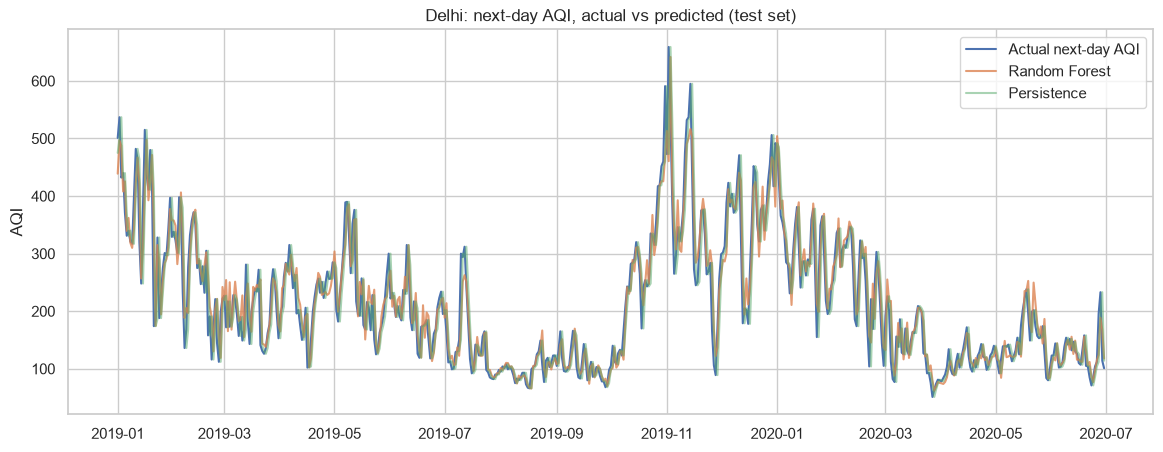

In [3]:
test_df = df[~train].reset_index(drop=True)
mask = (test_df["City"] == "Delhi").values
dates = test_df.loc[mask, "Date"]

plt.figure(figsize=(14, 5))
plt.plot(dates, y_test.values[mask], label="Actual next-day AQI", linewidth=1.5)
plt.plot(dates, preds["Random Forest"][mask], label="Random Forest", alpha=0.8)
plt.plot(dates, preds["Persistence (tomorrow = today)"][mask], label="Persistence", alpha=0.5)
plt.ylabel("AQI")
plt.title("Delhi: next-day AQI, actual vs predicted (test set)")
plt.legend()
plt.savefig(OUT / "14_next_day_delhi.png", dpi=150, bbox_inches="tight")
plt.show()

Actual vs predicted over time (Delhi)

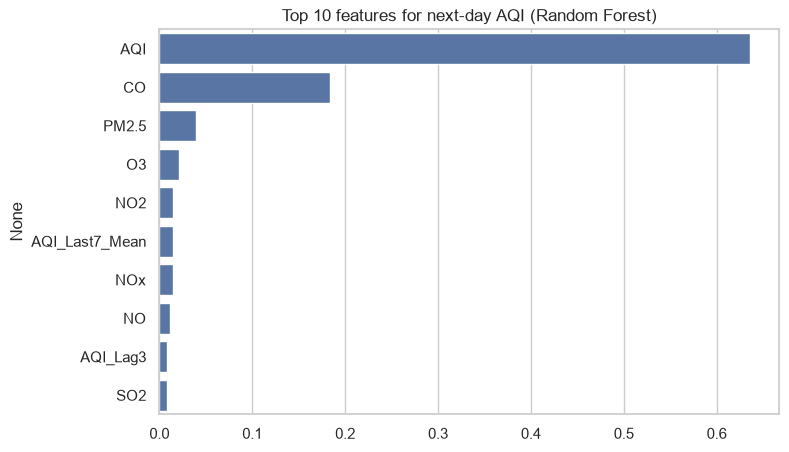

In [4]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index)
plt.title("Top 10 features for next-day AQI (Random Forest)")
plt.savefig(OUT / "15_next_day_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Feature Importance

In [5]:
print("Same-day Random Forest (notebook 02):  MAE 19.96, R2 0.883")
print("Next-day Random Forest (this notebook): MAE",
      round(mean_absolute_error(y_test, preds["Random Forest"]), 2),
      ", R2", round(r2_score(y_test, preds["Random Forest"]), 3))

Same-day Random Forest (notebook 02):  MAE 19.96, R2 0.883
Next-day Random Forest (this notebook): MAE 22.73 , R2 0.834


Comparison with same day prediction